# XGBoost par axe

Un modèle indépendant par axe et par cible, évalué sur le même horizon temporel de 120 heures que le modèle global.

In [19]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

import dataset_create
importlib.reload(dataset_create)
from dataset_create import FEATURES, ORIGINES, charger, split

C:\Users\ltrav\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Donnees et origine du backtest

On reprend la meme origine que dans `data_explo.ipynb` : derniere donnee connue le vendredi 07/11/2025, puis test du 08 au 12/11. Cette fenetre contient des mesures reelles de Champs-Elysees avant l interruption du capteur.

In [14]:
df = charger()
features = FEATURES
BACKTEST_ORIGIN = "2025-11-07"  # same origin as data_explo.ipynb; test Nov 8-12, 2025

print("Période :", df["datetime"].min(), "->", df["datetime"].max())
print("Origine du backtest :", BACKTEST_ORIGIN)
print("Axes du dataset :", sorted(df["axe"].unique()))
print("Features :", features)


Période : 2014-01-01 01:00:00+01:00 -> 2026-11-01 00:00:00+01:00
Origine du backtest : 2025-11-07
Axes du dataset : ['Champs-Elysees', 'Convention', 'Saints-Peres']
Features : ['axe', 'heure', 'jour_sem', 'heure_sem', 'type_jour', 'mois', 'lag_7j', 'lag_14j', 'lag_moy', 'vacances', 'ferie', 'pont', 'paris_respire', 'evenement', 'confinement']


## Pr?paration des jeux train/test

Les mod?les sont entra?n?s s?par?ment pour chaque axe pr?sent dans le train. `axe` est donc retir? des variables explicatives; les variables calendrier, ?v?nements et historiques restent partag?es. Un axe sans observations r?centes peut quand m?me avoir un mod?le entra?n? sur son historique, mais ne peut pas ?tre ?valu? sans valeurs r?elles de test.

In [15]:
target_names = ["debit", "occupation"]
model_features = [feature for feature in features if feature != "axe"]
categorical_features = ["vacances"]
numeric_features = [feature for feature in model_features if feature not in categorical_features]

splits = {}
for target in target_names:
    X_train, X_test, y_train, y_test = split(
        df,
        BACKTEST_ORIGIN,
        cible=target,
        features=features,
    )
    splits[target] = (X_train, X_test, y_train, y_test)
    print(f"{target}: train={len(X_train):,}, test={len(X_test):,}")
    print("  observations de test par axe:", X_test["axe"].value_counts().to_dict())

debit: train=274,198, test=355
  observations de test par axe: {'Convention': 120, 'Saints-Peres': 119, 'Champs-Elysees': 116}
occupation: train=280,056, test=355
  observations de test par axe: {'Convention': 120, 'Saints-Peres': 119, 'Champs-Elysees': 116}


## Entraînement des modèles par axe

In [16]:
def create_model():
    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
            ("num", "passthrough", numeric_features),
        ]
    )
    regressor = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
    )
    return Pipeline([("preprocessor", preprocessor), ("xgb", regressor)])


models = {target: {} for target in target_names}
predictions = {target: {} for target in target_names}
results = []

for target in target_names:
    X_train, X_test, y_train, y_test = splits[target]
    for axe in sorted(X_train["axe"].unique()):
        train_mask = X_train["axe"] == axe
        test_mask = X_test["axe"] == axe
        X_train_axe = X_train.loc[train_mask, model_features]
        X_test_axe = X_test.loc[test_mask, model_features]
        y_train_axe = y_train.loc[train_mask]
        y_test_axe = y_test.loc[test_mask]

        model = create_model()
        model.fit(X_train_axe, y_train_axe)
        models[target][axe] = model

        if len(y_test_axe):
            y_pred = model.predict(X_test_axe)
            predictions[target][axe] = y_pred
            rmse_xgboost = np.sqrt(mean_squared_error(y_test_axe, y_pred))
            rmse_baseline = np.sqrt(mean_squared_error(
                y_test_axe, np.full(len(y_test_axe), y_train_axe.mean())
            ))
        else:
            predictions[target][axe] = np.array([])
            rmse_xgboost = np.nan
            rmse_baseline = np.nan
            print(f"{target} / {axe}: mod?le entra?n? sur {len(y_train_axe):,} observations; pas de test r?cent, RMSE indisponible.")

        results.append({
            "cible": target,
            "axe": axe,
            "n_train": len(y_train_axe),
            "n_test": len(y_test_axe),
            "rmse_xgboost": rmse_xgboost,
            "rmse_baseline": rmse_baseline,
        })

results_df = pd.DataFrame(results).sort_values(["cible", "axe"]).reset_index(drop=True)
results_df

,cible,axe,n_train,n_test,rmse_xgboost,rmse_baseline
0,debit,Champs-Elysees,96975,116,122.413341,438.542159
1,debit,Convention,86657,120,56.014835,228.599584
2,debit,Saints-Peres,90566,119,42.902915,189.112247
3,occupation,Champs-Elysees,96216,116,6.918361,9.266822
4,occupation,Convention,93270,120,2.453506,4.096555
5,occupation,Saints-Peres,90570,119,1.215503,3.133788


## R?sultats

Le RMSE est calcul? s?par?ment pour chaque axe. La baseline pr?dit la moyenne de la cible d?entra?nement du m?me axe. Pour Champs-?lys?es, le mod?le est entra?n? sur l?historique disponible, mais le RMSE reste vide faute de mesures r?elles dans l?horizon de test.

In [17]:
results_df

,cible,axe,n_train,n_test,rmse_xgboost,rmse_baseline
0,debit,Champs-Elysees,96975,116,122.413341,438.542159
1,debit,Convention,86657,120,56.014835,228.599584
2,debit,Saints-Peres,90566,119,42.902915,189.112247
3,occupation,Champs-Elysees,96216,116,6.918361,9.266822
4,occupation,Convention,93270,120,2.453506,4.096555
5,occupation,Saints-Peres,90570,119,1.215503,3.133788


## Prédictions de test

Les prédictions ci-dessous sont indexées par date et par axe, ce qui facilite leur comparaison avec le modèle global.

In [18]:
prediction_frames = []
for target in target_names:
    X_test = splits[target][1]
    y_test = splits[target][3]
    for axe, y_pred in predictions[target].items():
        if len(y_pred) == 0:
            continue
        mask = X_test["axe"] == axe
        prediction_frames.append(pd.DataFrame({
            "datetime": df.loc[X_test.index[mask], "datetime"].to_numpy(),
            "axe": axe,
            "cible": target,
            "valeur_reelle": y_test.loc[mask].to_numpy(),
            "prediction": y_pred,
        }))

predictions_df = pd.concat(prediction_frames, ignore_index=True)
predictions_df.head()

,datetime,axe,cible,valeur_reelle,prediction
0,2025-11-08 00:00:00+01:00,Champs-Elysees,debit,926.0,896.242676
1,2025-11-08 01:00:00+01:00,Champs-Elysees,debit,979.0,922.480347
2,2025-11-08 02:00:00+01:00,Champs-Elysees,debit,737.0,813.187927
3,2025-11-08 03:00:00+01:00,Champs-Elysees,debit,652.0,754.482849
4,2025-11-08 04:00:00+01:00,Champs-Elysees,debit,674.0,607.399170


## Analyse SHAP par cible et par axe

Pour chaque modèle entraîné, affiche l’importance globale des features (barres) et leur effet sur les prédictions (beeswarm), comme dans le notebook global.

SHAP - debit / Champs-Elysees


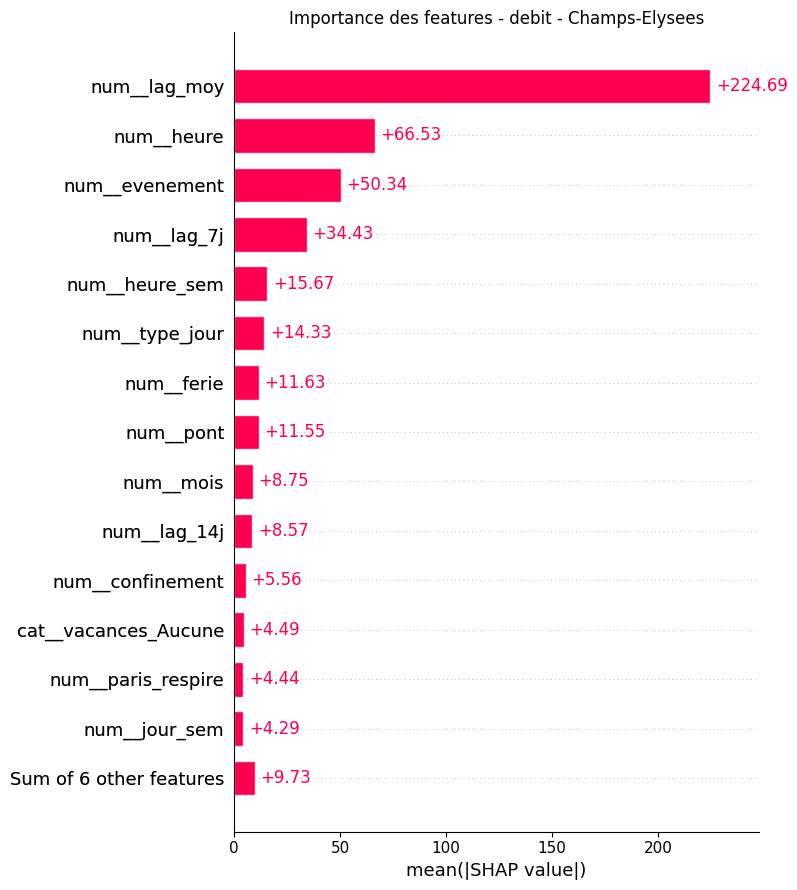

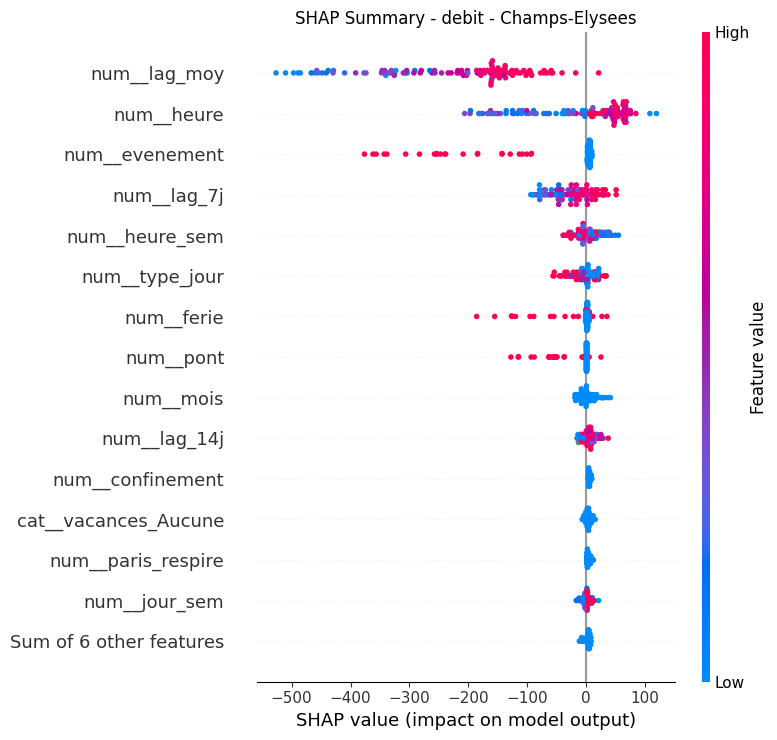

SHAP - debit / Convention


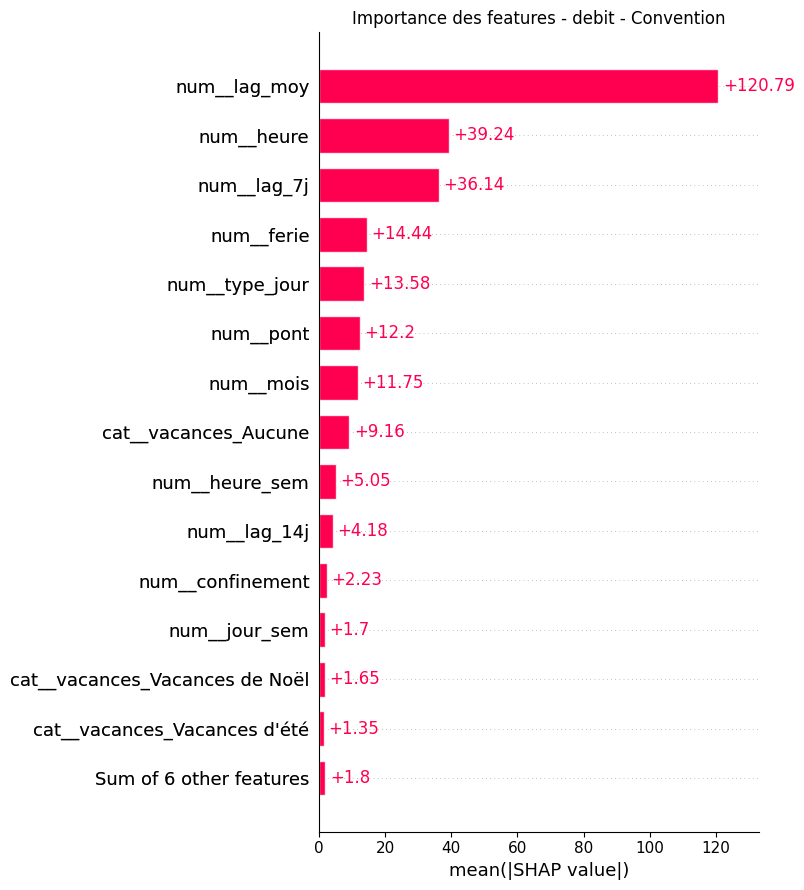

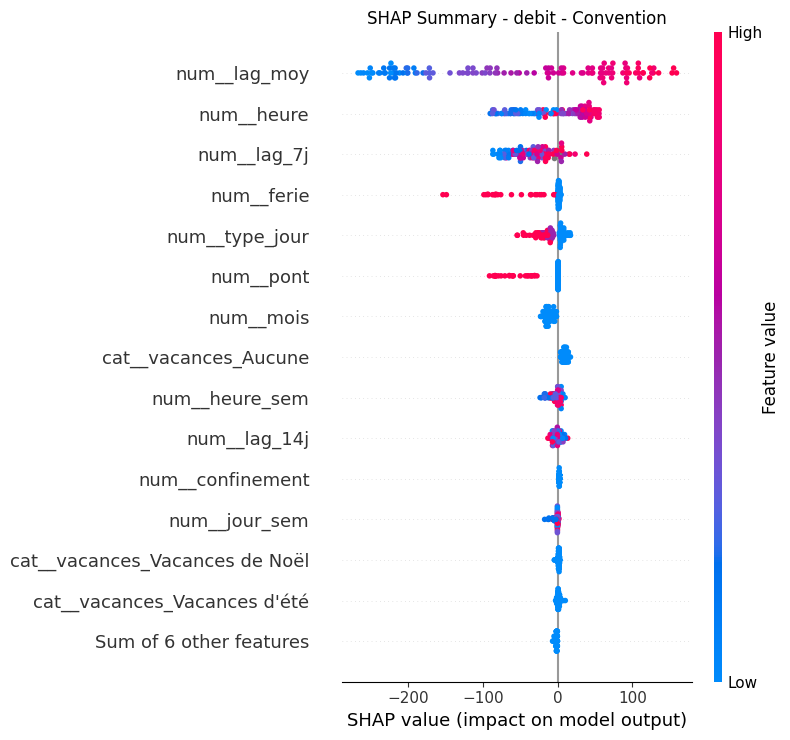

SHAP - debit / Saints-Peres


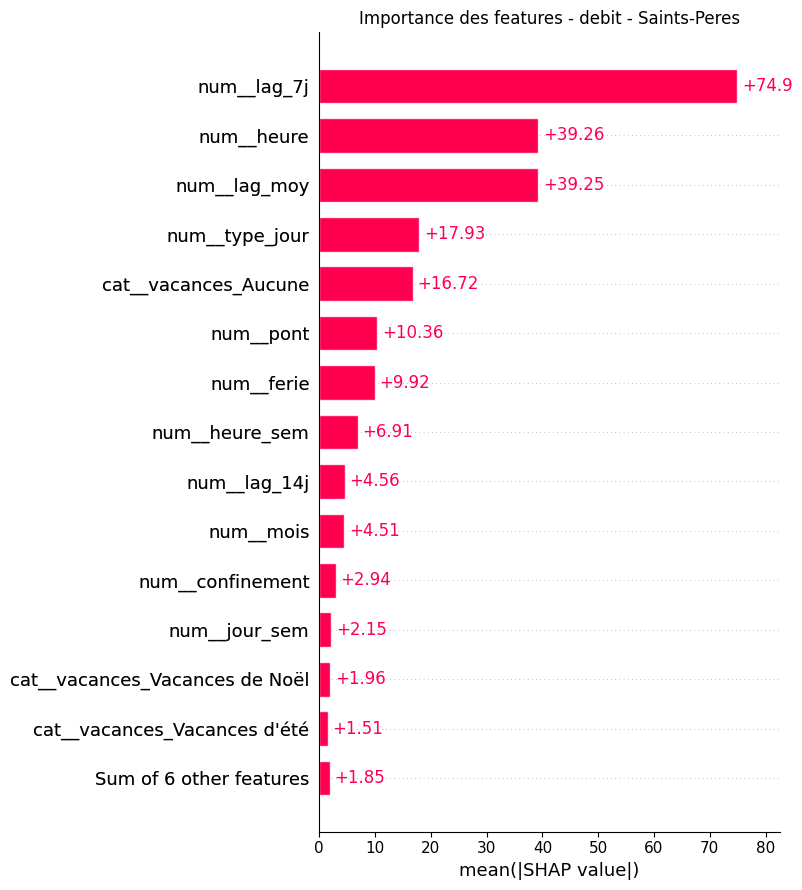

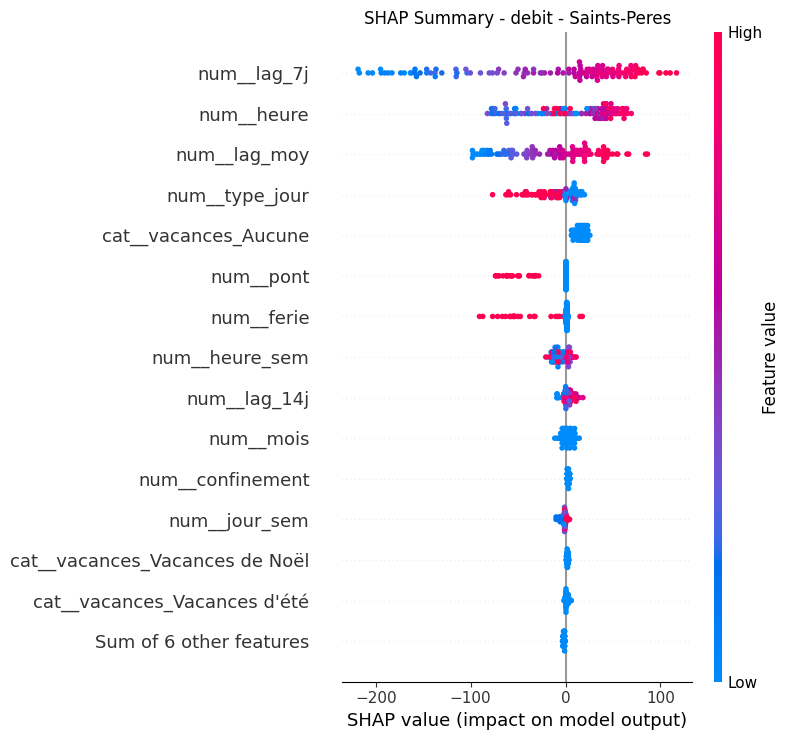

SHAP - occupation / Champs-Elysees


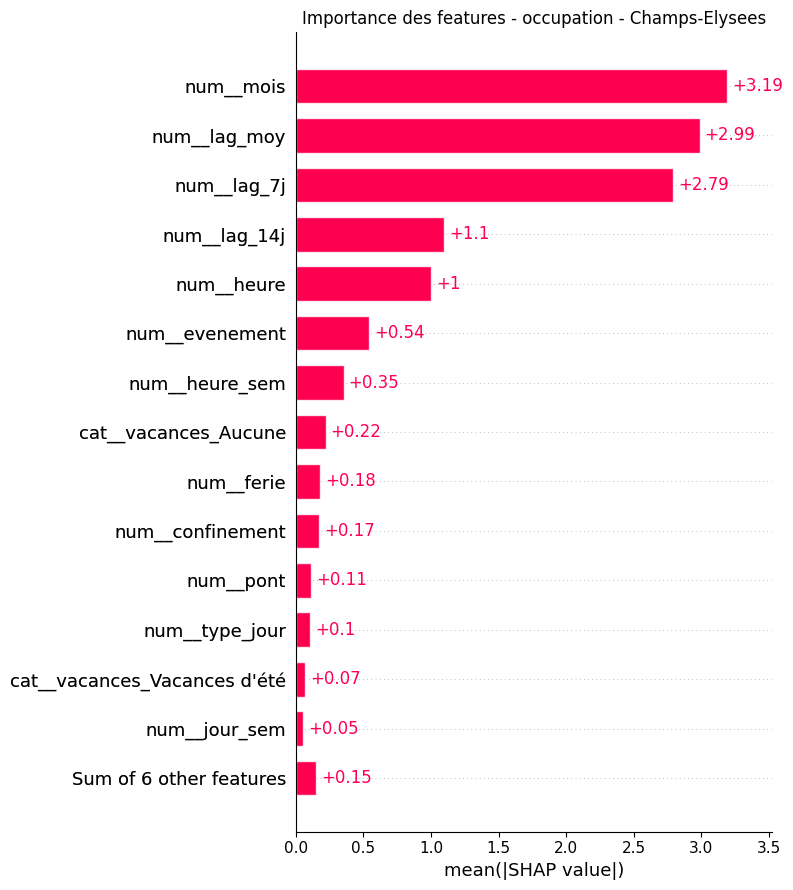

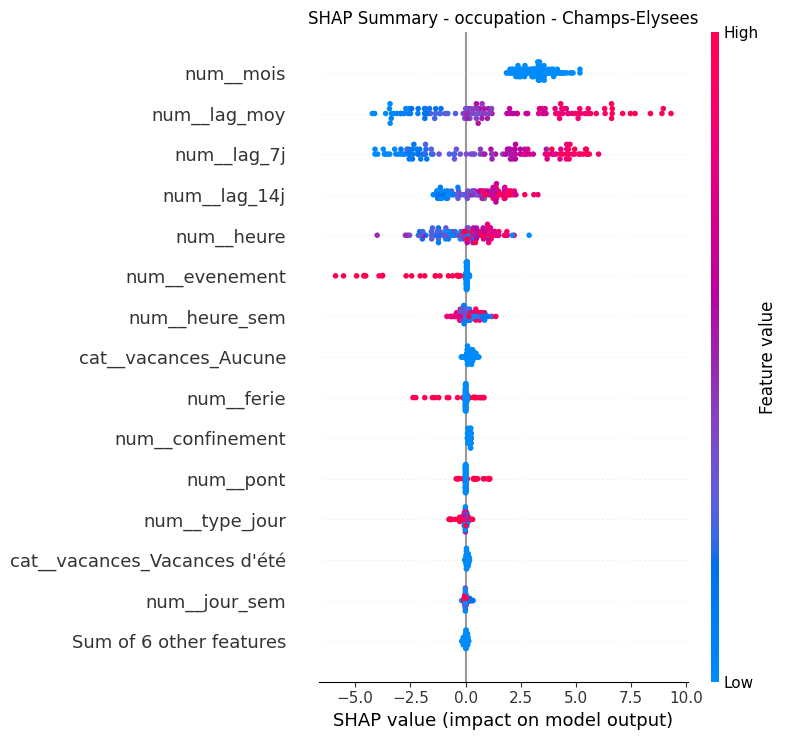

SHAP - occupation / Convention


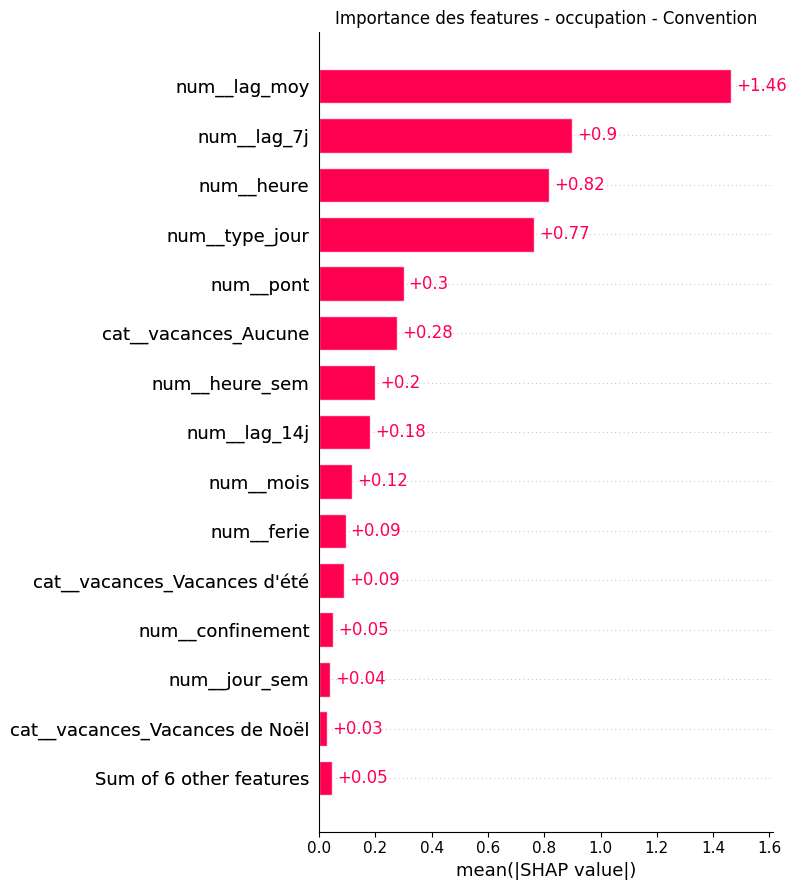

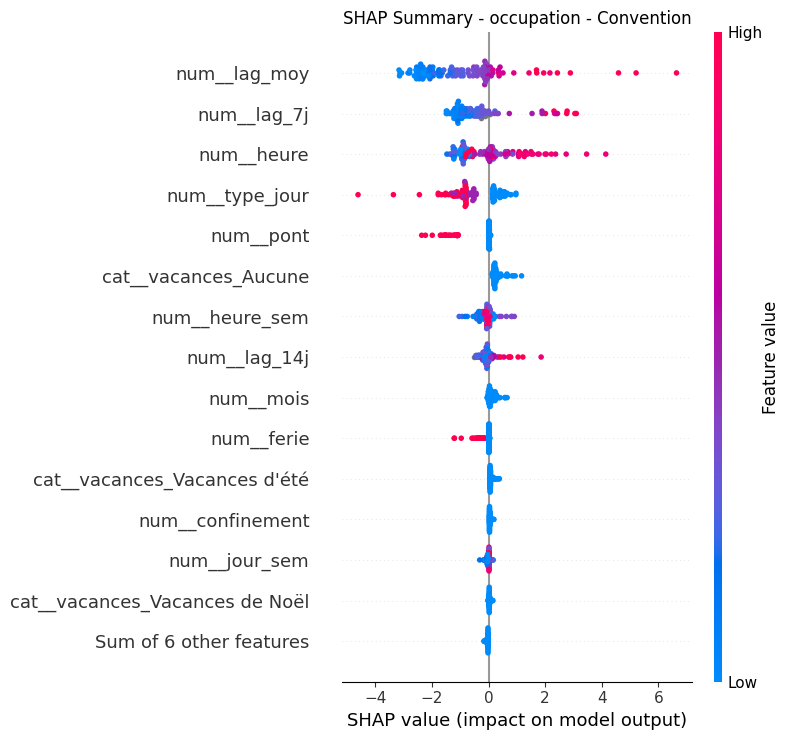

SHAP - occupation / Saints-Peres


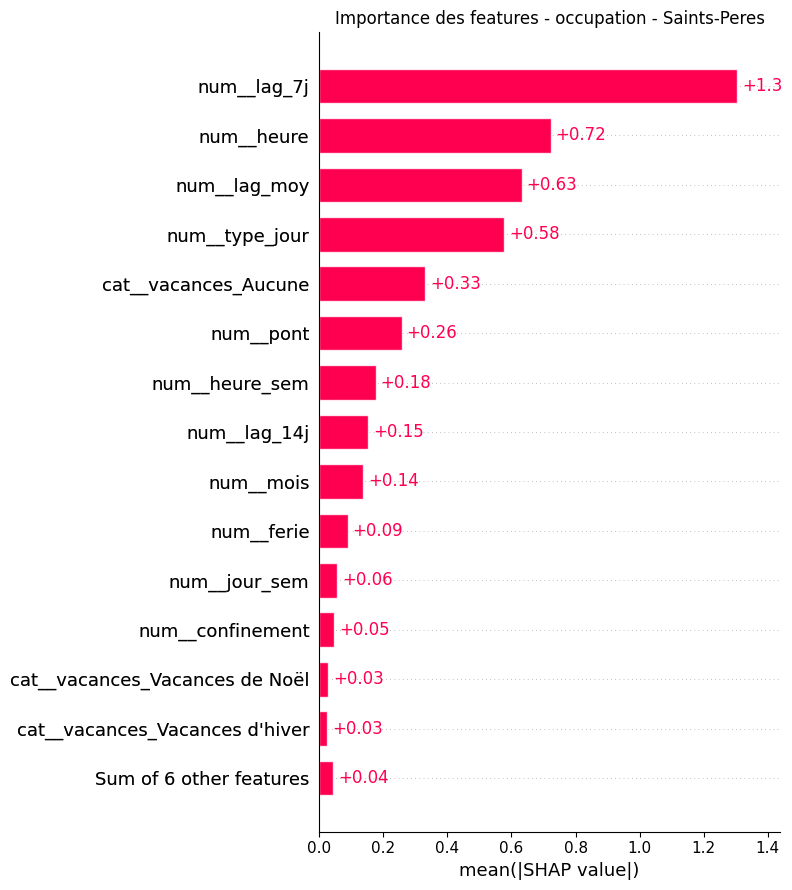

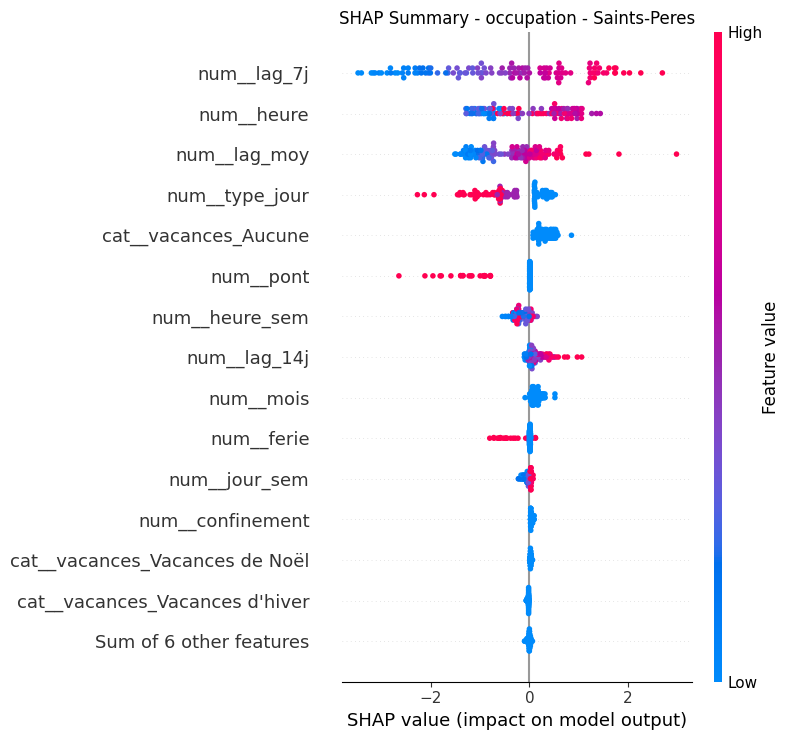

In [20]:
def analyser_shap_par_axe(model, X_test_axe, nom_cible, nom_axe):
    X_sample = X_test_axe.sample(
        n=min(1000, len(X_test_axe)),
        random_state=42,
    )

    preprocessor = model.named_steps["preprocessor"]
    xgb_model = model.named_steps["xgb"]
    X_transformed = preprocessor.transform(X_sample)
    if hasattr(X_transformed, "toarray"):
        X_transformed = X_transformed.toarray()

    feature_names = preprocessor.get_feature_names_out()
    X_shap = pd.DataFrame(X_transformed, columns=feature_names, index=X_sample.index)
    shap_values = shap.TreeExplainer(xgb_model)(X_shap)

    plt.figure()
    shap.plots.bar(shap_values, max_display=15, show=False)
    plt.title(f"Importance des features - {nom_cible} - {nom_axe}")
    plt.tight_layout()
    plt.show()

    plt.figure()
    shap.plots.beeswarm(shap_values, max_display=15, show=False)
    plt.title(f"SHAP Summary - {nom_cible} - {nom_axe}")
    plt.tight_layout()
    plt.show()

    return shap_values


shap_values_by_model = {}
for target in target_names:
    X_test = splits[target][1]
    for axe, model in models[target].items():
        X_test_axe = X_test.loc[X_test["axe"] == axe, model_features]
        if X_test_axe.empty:
            print(f"Pas de données de test pour {target} / {axe}; analyse SHAP ignorée.")
            continue

        print(f"SHAP - {target} / {axe}")
        shap_values_by_model[(target, axe)] = analyser_shap_par_axe(
            model,
            X_test_axe,
            target,
            axe,
        )